# 4 · Build a land-cover pipeline

[Notebook 3](03_inputs.ipynb) trained Prithvi and wrote `LandCoverPredictor` to turn one prepared image into class logits. A model alone does not make a map: something has to prepare the raw bands, run the model over a scene of any size and turn logits into a class map with a legend. `RasterPipeline` holds those steps, each a small object with one job:

| Step | Takes | Returns |
| --- | --- | --- |
| Ingestor | a region and dates | one raw raster tree per acquisition |
| Preprocessor | raw raster tree | model-ready sample tree |
| Predictor | model and sample | class logits on the scene grid, a `DataArray` |
| Postprocessor | logits and sample | dated class map with its legend, a `Dataset` |

Build it one step at a time on a local validation image, save it, then map the KHDTK forest with the reloaded pipeline. Run from `examples/` in a fresh kernel after notebook 3. The forest section needs internet access.

## Load the trained model

Rebuild the chain from its saved stage definitions and load its weights.

In [1]:
from pathlib import Path

import numpy as np
import torch
import xarray as xr
import yaml

import geosave as gs
from geosave.ml import build_model

checkpoint = torch.load("data/landcover_model.pt", map_location="cpu", weights_only=True)
model = build_model(checkpoint["stages"]).eval()
model.load_state_dict(checkpoint["state_dict"])

<All keys matched successfully>

## Prepare the model input

Notebook 3's Dataset kept the four bands in model order, decoded them to reflectance and filled missing pixels with zero. `DensePreprocessor` does exactly that to a tree of raw rasters, lazily. Training and inference then prepare an image the same way.

Open a validation image as stored, without decoding, and put it in a tree under the node name `image`, the name Prithvi takes its pixels by.

In [2]:
from geosave.ml import DensePreprocessor

root = Path("data/dynamic_world")
val_images = sorted((root / "image" / "val").glob("*.tif"))
scene = gs.open_raster(val_images[0])
rasters = scene.gs.to_tree("image")

bands = ["B02", "B03", "B04", "B08"]
preprocessor = DensePreprocessor(bands)
sample = preprocessor(rasters)
sample

<xarray.DataTree>
Group: /
└── Group: /image
        Dimensions:         (y: 510, x: 510)
        Coordinates:
          * y               (y) float64 4kB 2.229e+06 2.229e+06 ... 2.224e+06 2.224e+06
          * x               (x) float64 4kB 3.703e+05 3.704e+05 ... 3.754e+05 3.754e+05
            spatial_ref     int32 4B 32614
            time            datetime64[us] 8B 2019-01-30T17:15:41
            start_datetime  datetime64[ns] 8B 2019-01-30T17:15:41.024000
            end_datetime    datetime64[ns] 8B 2019-01-30T17:15:41.024000
        Data variables:
            B02             (y, x) float32 1MB dask.array<chunksize=(510, 510), meta=np.ndarray>
            B03             (y, x) float32 1MB dask.array<chunksize=(510, 510), meta=np.ndarray>
            B04             (y, x) float32 1MB dask.array<chunksize=(510, 510), meta=np.ndarray>
            B08             (y, x) float32 1MB dask.array<chunksize=(510, 510), meta=np.ndarray>
        Attributes:
            rgb:              ["B04","B03","B02"]
            stac_collection:  {"type":"Collection","id":"sentinel-2-l2a","stac_versio...
            stac_extensions:  ["https://stac-extensions.github.io/eo/v1.1.0/schema.js...
            AREA_OR_POINT:    Area

## Predict with notebook 3's predictor

Run the predictor definition from notebook 3. Its class header, `RasterPredictor[xr.DataArray]`, states what it hands to the next step: merged logits as a DataArray on the sample's grid.

Each step is called directly, so you can look at what it returns. Convert the logits to probabilities and map the probability of the winning class: low values show where the model hesitates.

In [3]:
from itertools import batched

from torch import nn
from torch.utils.data import default_collate

from geosave.ml import RasterPredictor


class LandCoverPredictor(RasterPredictor[xr.DataArray]):
    def __init__(self, size: int = 128, stride: int = 64, batch_size: int = 16):
        self.size = size
        self.stride = stride
        self.batch_size = batch_size

    def measure_chips(self) -> tuple[int, int]:
        return self.size, self.stride

    def __call__(self, model: nn.Module, sample: xr.DataTree) -> xr.DataArray:
        chips = gs.RasterChipper([sample], size=self.size, stride=self.stride)
        merger = gs.RasterMerger(chips.layout, window="hann")
        device = next(model.parameters()).device

        for chip_indices in batched(range(len(chips)), self.batch_size):
            chip_inputs = []
            for index in chip_indices:
                pixels, context = chips[index].gs.to_tensor(context=["centroid", "year", "day_of_year"])
                chip_inputs.append({**pixels, **context})

            batch = default_collate(chip_inputs)
            inputs = {name: tensor.to(device) for name, tensor in batch.items()}
            with torch.inference_mode():
                batch_logits = model(**inputs).float().cpu().numpy()
            for index, chip_logits in zip(chip_indices, batch_logits, strict=True):
                merger.add(index, chip_logits)

        output = merger.merge()
        return output

:Image   [x,y]   (confidence)
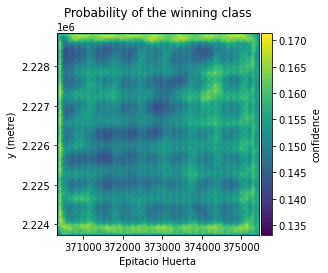

In [4]:
predictor = LandCoverPredictor(size=128, stride=64, batch_size=16)
logits = predictor(model, sample)

probabilities = np.exp(logits - logits.max("band"))
probabilities = probabilities / probabilities.sum("band")
confidence = probabilities.max("band").rename("confidence")
confidence.gs.plot(title="Probability of the winning class")

## Decode the logits into a land-cover map

`SegmentationPostprocessor` picks the highest-scoring class at each pixel, attaches the class names and colours from the training label scheme and keeps the acquisition date of the sample. Pixels no chip covered get the nodata value 255.

:Layout
   .RGB.I     :RGB   [x,y]   (R,G,B)
   .Overlay.I :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Shrub_and_scrub    :Points   [x,y]
      .Points.Built              :Points   [x,y]
      .Points.Bare               :Points   [x,y]
      .Points.Snow_and_ice       :Points   [x,y]
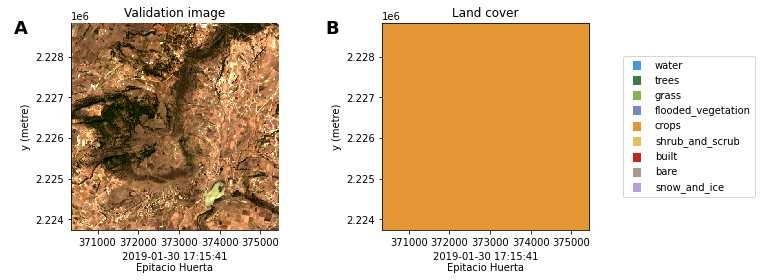

In [5]:
from geosave.ml import SegmentationPostprocessor

target = yaml.safe_load((root / "labels.yaml").read_text())["dynamic_world"]
postprocessor = SegmentationPostprocessor(target["classes"], target["colors"])

cover = postprocessor(logits, sample)
scene.gs.plot(rgb=("B04", "B03", "B02"), title="Validation image") + cover["class_id"].gs.plot(title="Land cover")

## Assemble the pipeline

`RasterPipeline` runs the three steps you just called, in the same order:

```python
sample = preprocessor(rasters)
output = predictor(model, sample)
product = postprocessor(output, sample)
```

Each handoff has one type. The predictor's class header says it returns a `DataArray`, and `SegmentationPostprocessor` is a `RasterPostprocessor[xr.DataArray, xr.Dataset]`: it takes a `DataArray` and returns a `Dataset`. A type checker refuses a predictor and postprocessor that disagree. Check that the pipeline reproduces the map from the individual steps.

In [6]:
from geosave.ml import RasterPipeline

pipeline = RasterPipeline(model, preprocessor, predictor, postprocessor)
pipeline.predict(rasters).identical(cover)

True

## Move the experiment into the library

A release names the class of each step so that someone else can rebuild the pipeline. `LandCoverPredictor` lives in this notebook, so a colleague's Python could not import it. Once an experiment settles, its code moves into the library under a registered name. `DensePredictor` is notebook 3's loop with the chip size, stride, batch size and context as arguments. Check that it returns the same logits.

In [7]:
from geosave.ml import DensePredictor

library_predictor = DensePredictor(
    size=128, stride=64, batch_size=16, context=["centroid", "year", "day_of_year"]
)
np.allclose(library_predictor(model, sample), logits, equal_nan=True)

True

## Save and reload the pipeline

Give the pipeline the library predictor and a Sentinel-2 ingestor for the same four bands. The release stores the model weights and each step by its registered name and arguments, so `load_pipeline` rebuilds it wherever GeoSave is installed, no notebook cells needed.

In [8]:
import json

from geosave.ml import Sentinel2Ingestor
from geosave.ml.release import ChainModel, load_pipeline

pipeline = RasterPipeline(
    model,
    preprocessor=preprocessor,
    predictor=library_predictor,
    postprocessor=postprocessor,
    ingestor=Sentinel2Ingestor(bands),
)
release = Path("data/landcover_pipeline")
ChainModel.from_pipeline(pipeline).save_pretrained(release)

config = json.loads((release / "config.json").read_text())
{step: config[step]["name"] for step in ("ingestor", "preprocessor", "predictor", "postprocessor")}

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'ingestor': 'sentinel2_l2a',
 'preprocessor': 'dense',
 'predictor': 'dense',
 'postprocessor': 'segmentation'}

In [9]:
reloaded = load_pipeline(release)
reloaded.predict(rasters).equals(cover)

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

True

## Map the KHDTK forest

Use the search from [notebook 2](02_sources.ipynb) to find the least cloudy Sentinel-2 observation of the forest in August 2019. Give the reloaded ingestor the forest boundary on that day. It returns one raw raster tree per acquisition, here one, in stored digital numbers with their reflectance decoding stated.

In [10]:
boundary = gs.open_vector("khdtk.geojson")
forest = gs.GeoRegion.from_geometry(boundary, timespan="2019-08")

client = gs.StacClient.planetary_computer()
query = gs.StacQuery(collections=["sentinel-2-l2a"], max_items=1)
query = query.set_region(forest).sort_by("properties.eo:cloud_cover")
clearest = client.search_items(query)[0]

acquisitions = reloaded.ingestor(forest.set_time(f"{clearest.datetime:%Y-%m-%d}"))
forest_rasters = acquisitions[0]
forest_rasters

<xarray.DataTree>
Group: /
└── Group: /image
        Dimensions:         (y: 192, x: 168)
        Coordinates:
          * y               (y) float64 2kB 9.215e+06 9.215e+06 ... 9.213e+06 9.213e+06
          * x               (x) float64 1kB 4.368e+05 4.368e+05 ... 4.385e+05 4.385e+05
            spatial_ref     int32 4B 32749
            time            datetime64[ns] 8B 2019-08-02T02:35:59.024000
            start_datetime  datetime64[ns] 8B 2019-08-02T02:35:59.024000
            end_datetime    datetime64[ns] 8B 2019-08-02T02:35:59.024000
        Data variables:
            B02             (y, x) uint16 65kB dask.array<chunksize=(192, 168), meta=np.ndarray>
            B03             (y, x) uint16 65kB dask.array<chunksize=(192, 168), meta=np.ndarray>
            B04             (y, x) uint16 65kB dask.array<chunksize=(192, 168), meta=np.ndarray>
            B08             (y, x) uint16 65kB dask.array<chunksize=(192, 168), meta=np.ndarray>
        Attributes:
            rgb:              ["B04","B03","B02"]
            stac_collection:  {"type":"Collection","id":"sentinel-2-l2a","stac_versio...
            stac_extensions:  ["https://stac-extensions.github.io/eo/v1.1.0/schema.js...

:Layout
   .RGB.I     :RGB   [x,y]   (R,G,B)
   .Overlay.I :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Shrub_and_scrub    :Points   [x,y]
      .Points.Built              :Points   [x,y]
      .Points.Bare               :Points   [x,y]
      .Points.Snow_and_ice       :Points   [x,y]
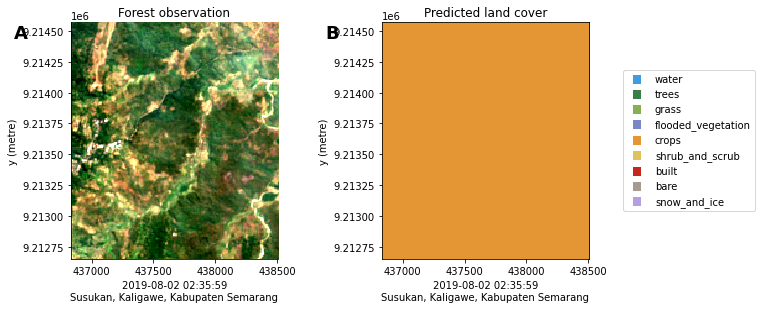

In [11]:
forest_cover = reloaded.predict(forest_rasters)

forest_image = forest_rasters["image"].to_dataset().gs.mask_and_scale()
forest_image.gs.plot(rgb=("B04", "B03", "B02"), title="Forest observation") + forest_cover["class_id"].gs.plot(title="Predicted land cover")

## Save the dated map

A prediction is a raster like any other. `publish_item` writes it as a cloud-optimized GeoTIFF with a STAC Item dated like the observation it was predicted from, ready for a catalog or a GIS.

In [12]:
item = forest_cover.gs.publish_item("data/khdtk_maps", id=f"{clearest.datetime:%Y%m%d}", overwrite=True)
item.datetime, list(item.assets)

(datetime.datetime(2019, 8, 2, 2, 35, 59, 24000, tzinfo=datetime.timezone.utc),
 ['class_id'])

## Explore further

### Map a larger area

`pipeline.predict` holds a scene's logits in memory. `pipeline.predict_to_zarr(rasters, "forest.zarr")` predicts and writes one chunk at a time. It asks the predictor for its chip size and stride, which is why `LandCoverPredictor` has `measure_chips`.

### Write a step of your own

Subclass a step's role and state its types, as `LandCoverPredictor` did. A postprocessor that leaves pixels below a probability threshold as nodata, for example, is a `RasterPostprocessor[xr.DataArray, xr.Dataset]`. When it works, move it into the library so a release can name it.

### Other kinds of input

A pipeline is defined by what you give it. `RasterPipeline` takes one acquisition, with any number of sensors as nodes of the tree. Change detection takes two acquisitions, `ChangePipeline.predict(before, after)`. A promptable model such as SAM takes rasters and the shapes to look at, `PromptPipeline.predict(rasters, prompts)`.